# Telecom Customer Churn Prediction

**Goal:** build a classification model that predicts whether a telecom customer will churn
(leave) or stay, using their demographic details, usage patterns, billing information and
service feedback.

**Data:** `Telco_customer_churn.xlsx` - the IBM Telco customer churn dataset: 7,043 customers,
33 columns, target = `Churn Value` (1 = churn, 0 = stay).

**Notebook outline**
1. Data understanding (EDA)
2. Cleaning and column selection
3. Feature engineering
4. Preprocessing pipeline
5. Models
6. Evaluation
7. Conclusion

> **Note on the reference report:** the assignment mentions a reference report to take model
> inspiration from. It was not available when this notebook was written, so the model choices
> below are justified on their own merits rather than by citing the report.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")

RANDOM_STATE = 42          # used everywhere so results are reproducible
np.random.seed(RANDOM_STATE)

# One consistent plot style for the whole notebook
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#898781"
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e1e0d9",
    "axes.edgecolor": "#c3c2b7",
})
pd.set_option("display.max_columns", 40)

## 1. Data understanding (EDA)

### 1.1 First look

The column names in the file contain spaces (for example `Tenure Months`). Right after loading we
rename them to CamelCase (`TenureMonths`) so the rest of the code is easier to read.

In [2]:
raw = pd.read_excel("Telco_customer_churn.xlsx")      # needs the openpyxl package
print("Shape:", raw.shape)


def to_camel_case(column):
    # 'Tenure Months' -> 'TenureMonths' (names without spaces, such as 'CLTV', stay the same)
    return "".join(word[0].upper() + word[1:] for word in str(column).split())


df = raw.rename(columns=to_camel_case)
print("New column names:", list(df.columns))
df.head(3)

Shape: (7043, 33)
New column names: ['CustomerID', 'Count', 'Country', 'State', 'City', 'ZipCode', 'LatLong', 'Latitude', 'Longitude', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'TenureMonths', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'ChurnLabel', 'ChurnValue', 'ChurnScore', 'CLTV', 'ChurnReason']


,CustomerID,Count,Country,State,City,ZipCode,LatLong,Latitude,Longitude,Gender,SeniorCitizen,Partner,Dependents,TenureMonths,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ChurnLabel,ChurnValue,ChurnScore,CLTV,ChurnReason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved


In [3]:
# One table with the type, number of missing values and number of distinct values per column
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "example": df.iloc[0],
})
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())
overview

Duplicate rows       : 0
Duplicate CustomerIDs: 0


,dtype,missing,unique,example
CustomerID,str,0,7043,3668-QPYBK
Count,int64,0,1,1
Country,str,0,1,United States
State,str,0,1,California
City,str,0,1129,Los Angeles
ZipCode,int64,0,1652,90003
LatLong,str,0,1652,"33.964131, -118.272783"
Latitude,float64,0,1652,33.964131
Longitude,float64,0,1651,-118.272783
Gender,str,0,2,Male


**What we see**
- 7,043 customers and 33 columns, with no duplicate rows or duplicate `CustomerID`s.
- The only column with missing values is `ChurnReason` (5,174 missing). Section 1.4 shows why.
- `SeniorCitizen` is stored as Yes/No text here, not as 0/1.
- `TotalCharges` has the generic `object` type, so it is not purely numeric (checked next).
- Several columns are about location (`Country`, `State`, `City`, `ZipCode`, `LatLong`,
  `Latitude`, `Longitude`), and `Count` is a constant. They are dealt with in Section 2.

### 1.2 Is `TotalCharges` clean?

In [4]:
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")   # text such as " " becomes NaN
blank = total_numeric.isna()

print("Non-numeric (blank) TotalCharges values:", blank.sum())
print("Their raw values:", df.loc[blank, "TotalCharges"].unique())
print("TenureMonths of those customers:", df.loc[blank, "TenureMonths"].unique())
print("Customers with TenureMonths == 0 in total:", (df["TenureMonths"] == 0).sum())

Non-numeric (blank) TotalCharges values: 11
Their raw values: [' ']
TenureMonths of those customers: [0]
Customers with TenureMonths == 0 in total: 11


`TotalCharges` contains **11 blank strings**, and all 11 belong to customers with a tenure of
0 months: brand-new customers who have not received a bill yet. Their total charge is therefore
0, which is what the cleaning step fills in (Section 2.2).

### 1.3 Class balance of the target

In [5]:
overall_rate = df["ChurnValue"].mean() * 100

balance = df["ChurnLabel"].value_counts().to_frame("customers")
balance["share_%"] = (balance["customers"] / len(df) * 100).round(1)
print("ChurnLabel and ChurnValue agree on every row:",
      ((df["ChurnLabel"] == "Yes").astype(int) == df["ChurnValue"]).all())
balance

ChurnLabel and ChurnValue agree on every row: True


,customers,share_%
ChurnLabel,,
No,5174,73.5
Yes,1869,26.5


**26.5% of customers churn** and 73.5% stay, a ratio of about 1 : 2.8. That is a clear
imbalance: a model that always predicts "stay" would already be 73.5% accurate while catching no
churners at all. We therefore judge models on churn-class recall, F1 and ROC-AUC, not accuracy,
and use `class_weight="balanced"`.

`ChurnLabel` (Yes/No) is just a text copy of `ChurnValue` (1/0), so only one of them can be kept.

### 1.4 Leakage check: `ChurnReason`, `ChurnScore` and `CLTV`

Three columns look suspicious, because they may have been created *using* the churn outcome.
A column like that is called **leakage**: it makes a model look excellent in the notebook but is
not available for a customer we are trying to predict, so the model would fail in real use.

In [6]:
# ChurnReason: when is it filled in?
print("ChurnReason filled in, by churn outcome:")
display(pd.crosstab(df["ChurnReason"].notna().map({True: "reason given", False: "missing"}),
                    df["ChurnValue"].map({1: "churned", 0: "stayed"})))

# ChurnScore and CLTV: how strongly do they relate to churn on their own?
for col in ["ChurnScore", "CLTV"]:
    print(f"{col:10s} correlation with churn: {df[col].corr(df['ChurnValue']):+.3f}   "
          f"ROC-AUC if used alone as a score: {roc_auc_score(df['ChurnValue'], df[col]):.3f}")

ChurnReason filled in, by churn outcome:


ChurnValue,churned,stayed
ChurnReason,,
missing,0,5174
reason given,1869,0


ChurnScore correlation with churn: +0.665   ROC-AUC if used alone as a score: 0.942
CLTV       correlation with churn: -0.127   ROC-AUC if used alone as a score: 0.419


- **`ChurnReason` is filled in for every churner and for no one else.** Knowing whether it is
  filled in tells you the answer with 100% certainty. It is collected *after* a customer leaves,
  so it can never be used to predict churn.
- **`ChurnScore`** correlates 0.66 with churn and gives a ROC-AUC of 0.94 *on its own*. It is a
  score produced by IBM's own model, built with knowledge of the outcome. Using it would mean
  copying another model's answer, not learning from customer data.
- **`CLTV`** (customer lifetime value) is also an output of another model. It is only weakly
  related to churn (correlation -0.13), but it is not raw customer data either.

All three are removed before modelling (Section 2.1). `ChurnReason` is still useful for
*understanding* why customers leave, so the next chart looks at it. It is used for insight only,
never as a model input.

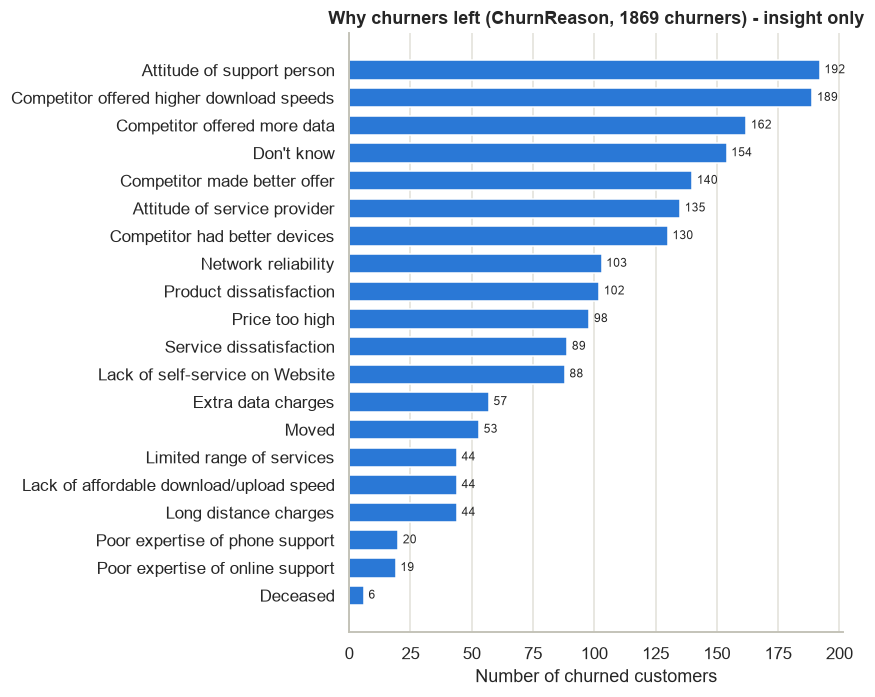

Reasons that start with 'Competitor': 621 of 1869 (33%)


In [7]:
reasons = df.loc[df["ChurnValue"] == 1, "ChurnReason"].value_counts()

plt.figure(figsize=(8, 6.5))
bars = plt.barh(reasons.index[::-1], reasons.values[::-1], color=BLUE, height=0.7)
plt.bar_label(bars, padding=3, fontsize=8)
plt.xlabel("Number of churned customers")
plt.title(f"Why churners left (ChurnReason, {reasons.sum()} churners) - insight only")
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

competitor = reasons[reasons.index.str.startswith("Competitor")].sum()
print(f"Reasons that start with 'Competitor': {competitor} of {reasons.sum()} ({competitor / reasons.sum():.0%})")

**Why churners left.** The reasons fall into a few clear themes:
- **Competitors** - a third of all churners (621 of 1,869) left for a better offer, faster
  download speeds, more data or better devices.
- **Service and support attitude** - "Attitude of support person" is the single most common
  reason (192), and "Attitude of service provider" adds another 135.
- **Network and product quality** - network reliability, product and service dissatisfaction.
- **Price** - "Price too high", extra data charges and long-distance charges.

This shapes the business recommendations in Section 7, but it cannot be a model input.

### 1.5 Churn rate against the key drivers

Each bar shows the **percentage of customers in that group who churned**. The dashed line is
the overall churn rate, so a bar above the line marks a riskier-than-average group.

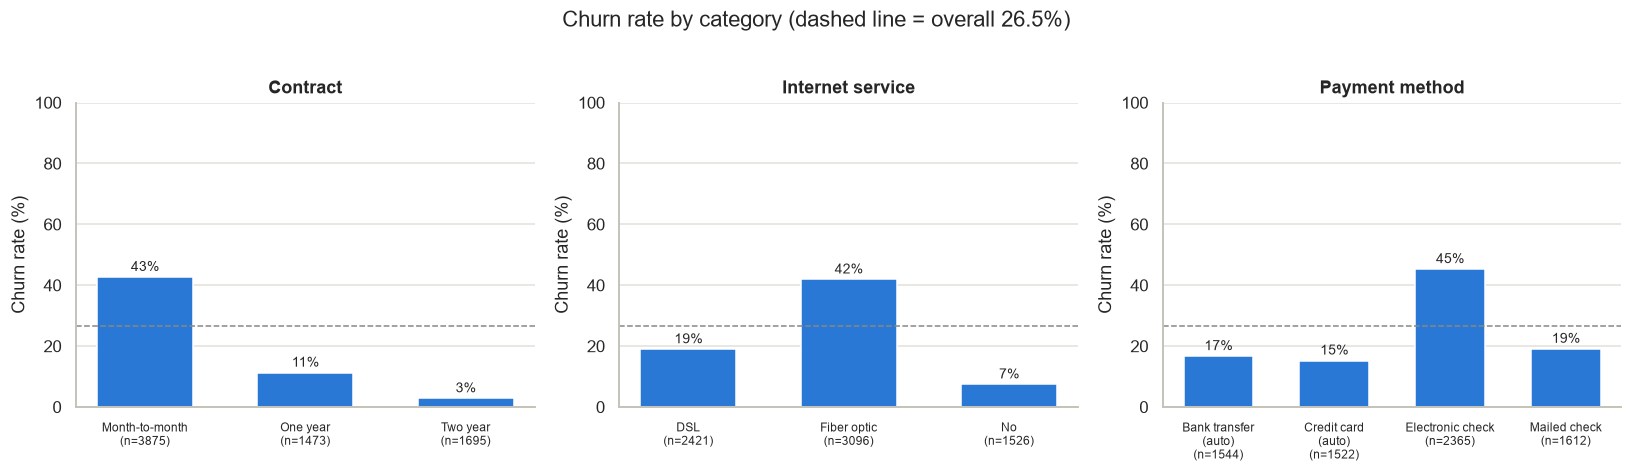

In [8]:
def plot_churn_rate(ax, groups, title, xlabel=""):
    # Bar chart of churn rate (%) for each group, with the group size under each label.
    stats = df.groupby(groups, observed=True)["ChurnValue"].agg(["mean", "count"])
    labels = [f"{idx}\n(n={n})" for idx, n in zip(stats.index, stats["count"])]
    bars = ax.bar(labels, stats["mean"] * 100, color=BLUE, width=0.6)
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
    ax.axhline(overall_rate, color=GREY, linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8)


payment_short = df["PaymentMethod"].str.replace(" (automatic)", "\n(auto)", regex=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
plot_churn_rate(axes[0], df["Contract"], "Contract")
plot_churn_rate(axes[1], df["InternetService"], "Internet service")
plot_churn_rate(axes[2], payment_short, "Payment method")
fig.suptitle(f"Churn rate by category (dashed line = overall {overall_rate:.1f}%)", y=1.02)
plt.tight_layout()
plt.show()

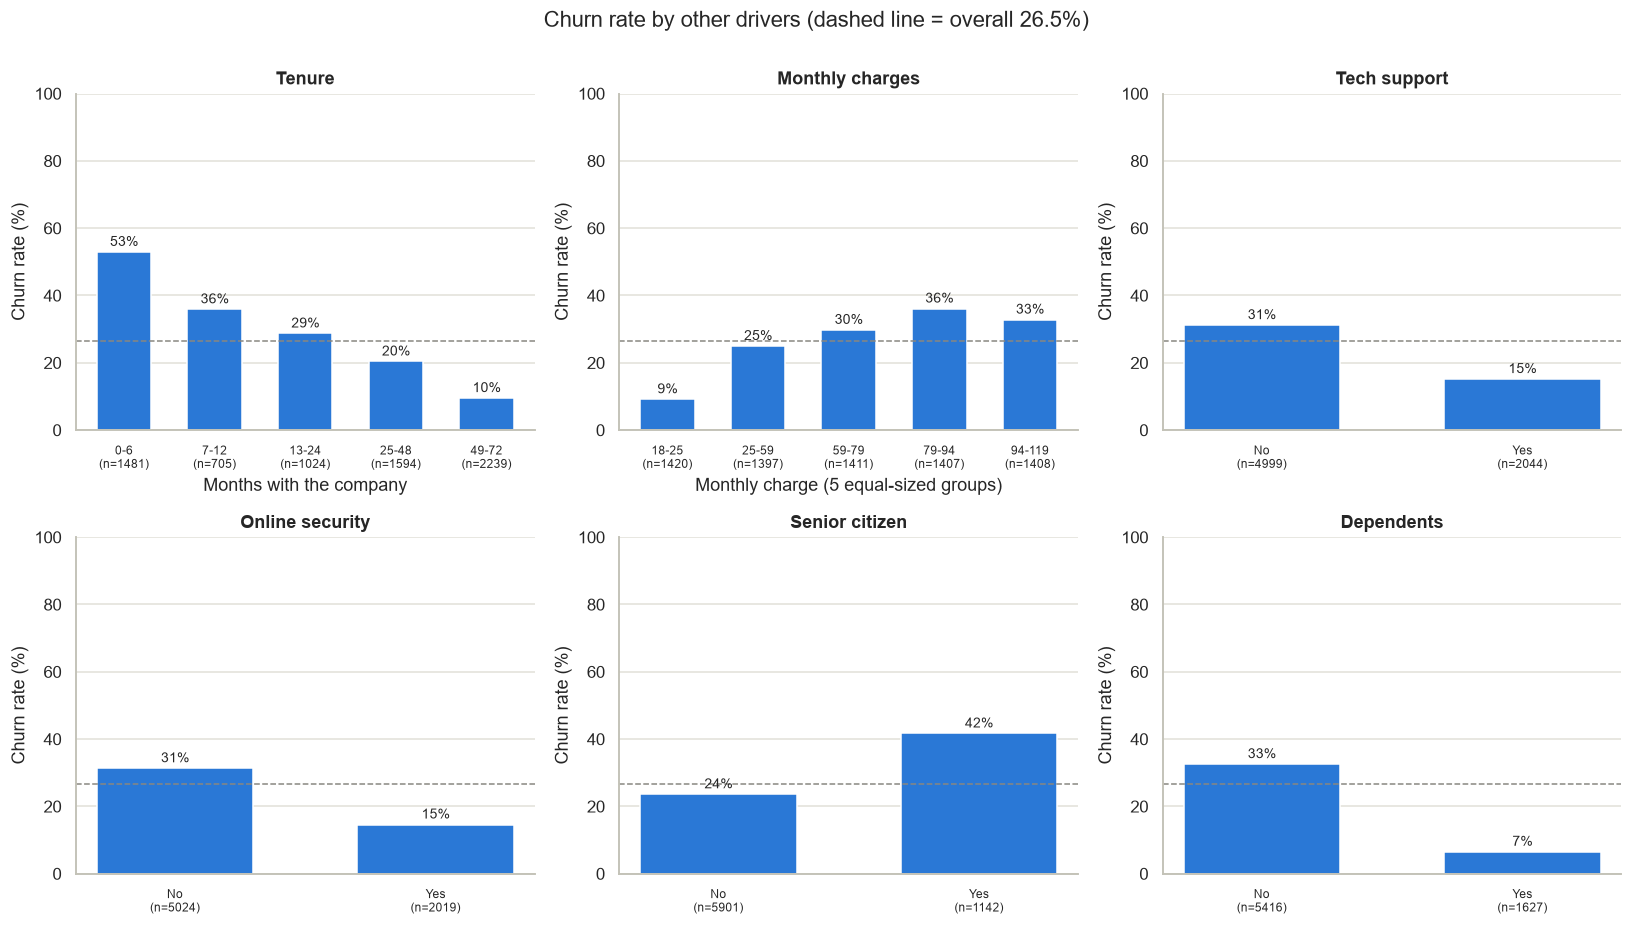

In [9]:
tenure_bins = pd.cut(df["TenureMonths"], [-1, 6, 12, 24, 48, 72],
                     labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
charge_bins = pd.qcut(df["MonthlyCharges"], 5).apply(lambda b: f"{b.left:.0f}-{b.right:.0f}")
no_internet_as_no = {"No internet service": "No"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8.4))
axes = axes.ravel()
plot_churn_rate(axes[0], tenure_bins, "Tenure", "Months with the company")
plot_churn_rate(axes[1], charge_bins, "Monthly charges", "Monthly charge (5 equal-sized groups)")
plot_churn_rate(axes[2], df["TechSupport"].replace(no_internet_as_no), "Tech support")
plot_churn_rate(axes[3], df["OnlineSecurity"].replace(no_internet_as_no), "Online security")
plot_churn_rate(axes[4], df["SeniorCitizen"], "Senior citizen")
plot_churn_rate(axes[5], df["Dependents"], "Dependents")
fig.suptitle(f"Churn rate by other drivers (dashed line = overall {overall_rate:.1f}%)", y=1.0)
plt.tight_layout()
plt.show()

**Reading the plots**
- **Contract** is the strongest single driver: 43% of month-to-month customers churn, against
  11% on one-year and only 3% on two-year contracts.
- **Internet service:** fiber-optic customers churn at 42%, more than twice the DSL rate (19%);
  customers without internet hardly churn at all (7%).
- **Payment method:** electronic-check payers churn at 45%, roughly three times the rate of
  automatic payers (15-17%) and well above mailed-check payers (19%).
- **Tenure:** churn falls steadily from 53% in the first 6 months to 10% after 4 years.
- **Monthly charges:** the cheapest fifth churns least (9%); above that the rate is 25-36%.
- **Tech support / online security:** customers with these add-ons churn about half as often (15% vs 31%).
- **Senior citizens** churn more (42% vs 24%), and **customers with dependents** churn much less (7% vs 33%).

### 1.6 Correlation between numeric columns

The dataset has only three numeric customer columns (`TenureMonths`, `MonthlyCharges`,
`TotalCharges`). `ChurnScore` and `CLTV` are included to show how they compare with the target.

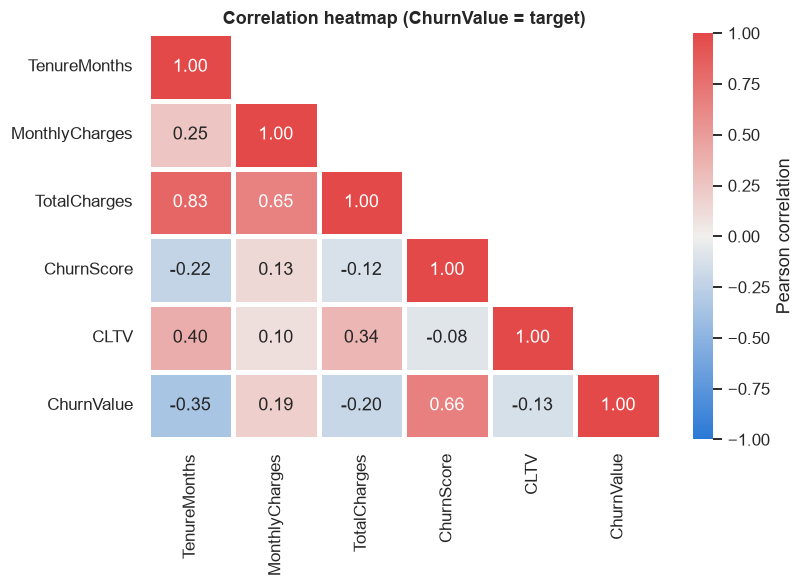

In [10]:
numeric = df[["TenureMonths", "MonthlyCharges", "ChurnScore", "CLTV", "ChurnValue"]].assign(
    TotalCharges=total_numeric.fillna(0))
numeric = numeric[["TenureMonths", "MonthlyCharges", "TotalCharges", "ChurnScore", "CLTV", "ChurnValue"]]
corr = numeric.corr()

# Blue = negative, red = positive, grey = no relationship
diverging = LinearSegmentedColormap.from_list("blue_grey_red", [BLUE, "#f0efec", RED])
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(corr, mask=mask, cmap=diverging, vmin=-1, vmax=1, annot=True, fmt=".2f",
            linewidths=2, linecolor="white", cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation heatmap (ChurnValue = target)")
plt.grid(False)
plt.tight_layout()
plt.show()

Correlation of TotalCharges with Tenure x MonthlyCharges: 0.9996


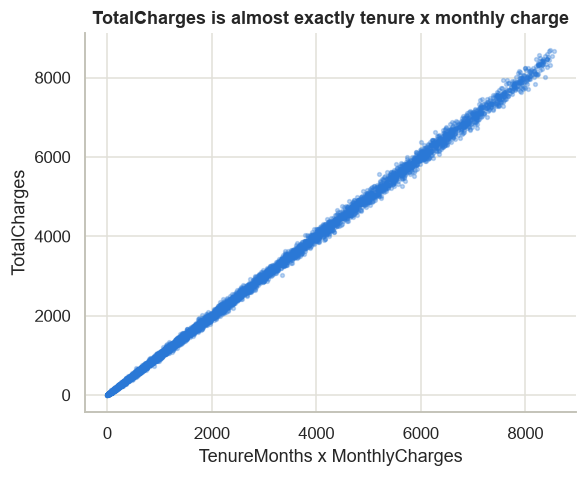

In [11]:
# Is TotalCharges just TenureMonths x MonthlyCharges?
expected_total = df["TenureMonths"] * df["MonthlyCharges"]
print("Correlation of TotalCharges with Tenure x MonthlyCharges:",
      round(total_numeric.fillna(0).corr(expected_total), 4))

plt.figure(figsize=(5.5, 4.5))
plt.scatter(expected_total, total_numeric.fillna(0), s=6, alpha=0.3, color=BLUE)
plt.xlabel("TenureMonths x MonthlyCharges")
plt.ylabel("TotalCharges")
plt.title("TotalCharges is almost exactly tenure x monthly charge")
plt.tight_layout()
plt.show()

**Decision on correlated and redundant columns**

| Pair | Correlation | Decision |
|---|---|---|
| `TotalCharges` vs `TenureMonths x MonthlyCharges` | 0.9996 | **Drop `TotalCharges` as a model input.** It is the product of two columns we already keep. It is still used to *build* the features `AvgChargePerMonth` and `ChargeDelta` |
| `TotalCharges` vs `TenureMonths` | 0.83 | Resolved by dropping `TotalCharges` |
| `TotalCharges` vs `MonthlyCharges` | 0.65 | Resolved by dropping `TotalCharges` |
| `ChurnScore` vs `ChurnValue` | 0.66 | Leakage - dropped (Section 2.1) |

`TenureMonths` (-0.35) and `MonthlyCharges` (+0.19) are the numeric columns most related to churn.

### 1.7 EDA summary - what was surprising

1. **Two leaking columns.** `ChurnReason` is filled in only for churners, and `ChurnScore` (an IBM
   model's output) reaches a ROC-AUC of 0.94 on its own. Both must be removed, or the model
   would simply read the answer.
2. **No service-feedback column.** The only feedback column (`ChurnReason`) is leakage, so one of the
   four problem-statement categories has to be covered by a proxy (Section 2.2).
3. **Clear imbalance (26.5% churn).** Accuracy would be misleading; we use `class_weight="balanced"`.
4. **`TotalCharges` is stored as text** with 11 blanks, all for tenure-0 customers, and it is
   redundant with `TenureMonths x MonthlyCharges` (correlation 0.9996).
5. **Strong categorical drivers.** Contract type (43% vs 3%), fiber internet (42%), electronic-check
   payment (45%) and dependents (7% vs 33%) separate churners much better than any numeric column.
6. **Location and ID columns** (`City`, `ZipCode`, coordinates, constant `Country`/`State`/`Count`)
   carry no usable signal for this problem and are dropped.

*EDA uses all 7,043 rows for description only. Everything that is **fitted** (scalers,
encoders, K-Means, models) is fitted on the training split only, from Section 2.3 onwards.*

## 2. Cleaning and column selection

### 2.1 Columns removed before modelling

| Column | Reason |
|---|---|
| `CustomerID` | Identifier, unique for every customer, no predictive value |
| `Count` | Always 1 |
| `Country`, `State` | Constant: every customer is in the United States / California |
| `City` | 1,129 different cities: far too sparse to learn from, and location is not part of the problem statement |
| `ZipCode`, `LatLong`, `Latitude`, `Longitude` | Location. The problem statement asks for demographic, usage, billing and feedback data, not geography |
| `ChurnLabel` | Duplicate of the target (`ChurnValue`) as Yes/No text |
| **`ChurnScore`** | **LEAKAGE.** A churn score from IBM's own model, computed with knowledge of who churned (correlation 0.66 with the target) |
| **`ChurnReason`** | **LEAKAGE.** Only filled in for customers who have *already* churned |
| `CLTV` | A predicted lifetime value from another model, not raw customer data. Dropped to keep the model honest (optional: it is only weakly related to churn and could be tested as an input) |

**Why the leakage drops matter most.** A model is meant to warn us about a customer *before*
they leave. At that moment `ChurnReason` does not exist yet, and `ChurnScore` is itself a churn
prediction made with hindsight. If either were kept, the model would reach a near-perfect score
in this notebook by reading the answer from these columns, then fail completely on real
customers. Section 1.4 showed the evidence: `ChurnReason` is filled in for exactly the 1,869
churners, and `ChurnScore` alone already gives a ROC-AUC of 0.94.

In [12]:
from sklearn.model_selection import train_test_split

DROP_COLUMNS = ["CustomerID", "Count", "Country", "State", "City", "ZipCode", "LatLong", "Latitude",
                "Longitude", "ChurnLabel", "ChurnScore", "ChurnReason", "CLTV"]

data = df.drop(columns=DROP_COLUMNS)
data = data.rename(columns={"ChurnValue": "Churn"})        # target: 1 = churn, 0 = stay
print("Columns left:", data.shape[1], "->", list(data.columns))

Columns left: 20 -> ['Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'TenureMonths', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### 2.2 Group the columns and apply the cleaning rules

The remaining inputs are grouped into the four categories named in the problem statement.

**This dataset has no service-feedback column.** `ChurnReason` *is* customer feedback, but it is
leakage (only known after the customer has left), so it cannot be used. As the closest available
proxy for the customer's experience of the service, we use the uptake of the support-type add-ons
`TechSupport` and `OnlineSecurity`, combined into the engineered feature `HasProtectionBundle`
(Section 3). The missing category is listed as a limitation in the conclusion.

`TotalCharges` is listed under billing but is used only to *derive* features (Section 2.5 explains why).

In [13]:
ADDON_SERVICES = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                  "StreamingTV", "StreamingMovies", "MultipleLines"]

COLUMN_GROUPS = {
    "Demographic": ["Gender", "SeniorCitizen", "Partner", "Dependents"],
    "Usage": ["TenureMonths", "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
              "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"],
    "Billing": ["Contract", "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges"],
    "Service feedback": [],      # none in this dataset - proxy: HasProtectionBundle (Section 3)
}
for group, columns in COLUMN_GROUPS.items():
    print(f"{group} ({len(columns)}): {', '.join(columns) if columns else 'NONE AVAILABLE'}")

grouped = sum(COLUMN_GROUPS.values(), [])
print("\nEvery input column is in exactly one group:", sorted(grouped) == sorted(data.columns.drop("Churn")))

Demographic (4): Gender, SeniorCitizen, Partner, Dependents
Usage (10): TenureMonths, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies
Billing (5): Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges
Service feedback (0): NONE AVAILABLE

Every input column is in exactly one group: True


These cleaning steps are fixed rules (nothing is *learned* from the data), so it is safe to apply
them to the whole dataset before splitting.

1. **`TotalCharges` to numbers.** The 11 blanks become missing values and are then rebuilt as
   `MonthlyCharges x TenureMonths`. All 11 customers have tenure 0, so this fills them with **0**.
2. **"No internet service" / "No phone service" -> "No".** For an add-on such as
   `OnlineSecurity`, "No internet service" simply means the customer does not have the add-on.
   `InternetService` and `PhoneService` already record *why*, so no information is lost.

In [14]:
# 1. TotalCharges: text -> numbers, blanks -> tenure x monthly charge (= 0 for tenure 0)
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
print("Blank TotalCharges filled:", data["TotalCharges"].isna().sum())
data["TotalCharges"] = data["TotalCharges"].fillna(data["MonthlyCharges"] * data["TenureMonths"])
print("Values used for them:", data.loc[data["TenureMonths"] == 0, "TotalCharges"].unique())

# 2. Normalise the "no service" labels
for col in ADDON_SERVICES:
    data[col] = data[col].replace({"No internet service": "No", "No phone service": "No"})

print("Values left in the add-on columns:", sorted(pd.unique(data[ADDON_SERVICES].values.ravel())))
print("Missing values left:", int(data.isna().sum().sum()))

Blank TotalCharges filled: 11
Values used for them: [0.]
Values left in the add-on columns: ['No', 'Yes']
Missing values left: 0


### 2.3 Train / test split

We split **now**, before looking at any statistic that will influence a modelling decision.
From here on, every test, every fitted step (scaler, encoder, K-Means) and every model uses the
**training set only**. The test set is touched once, in Section 6.

The split is 80/20 and *stratified*, so both parts keep the same 26.5% churn rate.

In [15]:
X = data.drop(columns="Churn")
y = data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, f"churn rate {y_train.mean():.1%}")
print("Test :", X_test.shape, f"churn rate {y_test.mean():.1%}")

Train: (5634, 19) churn rate 26.5%
Test : (1409, 19) churn rate 26.5%


### 2.4 Are the weak-looking columns worth keeping?

For every categorical column we compute, on the training set:
- **spread** - the gap in churn rate between its best and worst category (percentage points);
- a **chi-square test** p-value. A p-value above 0.05 means the column shows no statistically
  detectable link with churn.

In [16]:
train = X_train.assign(Churn=y_train)

categorical_columns = ["Gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
                       "InternetService", "Contract", "PaperlessBilling", "PaymentMethod"] + ADDON_SERVICES

rows = []
for col in categorical_columns:
    rates = train.groupby(col)["Churn"].mean() * 100
    p_value = chi2_contingency(pd.crosstab(train[col], train["Churn"]))[1]
    rows.append({"column": col,
                 "churn_rate_spread_pp": round(rates.max() - rates.min(), 1),
                 "chi2_p_value": round(p_value, 4),
                 "significant (p < 0.05)": "yes" if p_value < 0.05 else "no"})

pd.DataFrame(rows).set_index("column").sort_values("chi2_p_value")

,churn_rate_spread_pp,chi2_p_value,significant (p < 0.05)
column,,,
SeniorCitizen,17.4,0.0000,yes
Partner,12.9,0.0000,yes
Dependents,26.6,0.0000,yes
InternetService,34.8,0.0000,yes
PaperlessBilling,17.8,0.0000,yes
Contract,39.9,0.0000,yes
OnlineSecurity,17.0,0.0000,yes
PaymentMethod,30.8,0.0000,yes
TechSupport,16.1,0.0000,yes


In [17]:
# Numeric columns: correlation with the target (training set)
train[["TenureMonths", "MonthlyCharges", "TotalCharges"]].corrwith(train["Churn"]).round(3).to_frame(
    "correlation_with_churn")

,correlation_with_churn
TenureMonths,-0.346
MonthlyCharges,0.198
TotalCharges,-0.194


### 2.5 More dropped columns, and why

| Column | Reason for dropping |
|---|---|
| `Gender` | Churn rate is practically identical for men and women (spread 0.2 points, chi-square p = 0.89) |
| `PhoneService` | Not significant (spread 2.6 points, p = 0.20); 90% of customers have it |
| `TotalCharges` | Redundant: equals `TenureMonths x MonthlyCharges` (correlation 0.9996). It is still used to *build* two features in Section 3 |

All other categorical columns are significant (p < 0.05) and are kept. `MultipleLines` has the
smallest effect (spread 3.9 points, p = 0.001), but it is still significant.

## 3. Feature engineering

### 3.1 Candidate features

Each feature is listed with its problem-statement category and a one-line reason.

| Feature | Category | Definition | Why it might help |
|---|---|---|---|
| `NumServices` | Usage | Count of the 7 add-on services | How "embedded" a customer is; each extra service is a reason to stay |
| `HasStreaming` | Usage | Has `StreamingTV` or `StreamingMovies` | Streaming customers use the internet line more heavily |
| `IsFiber` | Usage | `InternetService` is fiber optic | EDA: fiber customers churn at 42% vs 19% for DSL |
| `NoInternet` | Usage | No internet service | EDA: only 7% of these customers churn |
| `IsNewCustomer` | Usage | `TenureMonths` <= 6 | EDA: 53% churn in the first 6 months |
| `TenureGroup` | Usage | Bins 0-12, 13-24, 25-48, 49+ months | Lets a linear model learn a non-linear tenure effect |
| `AvgChargePerMonth` | Billing | `TotalCharges` / max(`TenureMonths`, 1) | Average historical price paid |
| `ChargeDelta` | Billing | `MonthlyCharges` - `AvgChargePerMonth` | Positive = the price has gone up recently |
| `IsMonthToMonth` | Billing | `Contract` is month-to-month | EDA: 43% churn, against 11% and 3% on longer contracts |
| `AutoPay` | Billing | Payment method is automatic | EDA: automatic payers churn at 15-17% |
| `ElectronicCheck` | Billing | Pays by electronic check | EDA: 45% churn, the riskiest payment method by far |
| `HasProtectionBundle` | Service feedback (proxy) | Has `OnlineSecurity` or `TechSupport` | Customers who get support/security help churn much less (about 15% vs 42%) |
| `MonthToMonth_x_New` | Interaction | `IsMonthToMonth` and `IsNewCustomer` | New customers with no contract may be riskier than either factor alone |
| `Fiber_x_MonthToMonth` | Interaction | `IsFiber` and `IsMonthToMonth` | Fiber on a monthly contract combines the two strongest risk factors |
| `CustomerSegment` | Usage + Billing | K-Means cluster label | Groups customers with a similar tenure, bill and number of services |

All of these are built from columns that have no missing values, so they are computed directly
by `add_features`, followed by `SegmentAdder` for the K-Means segment - both *inside* the pipeline.

### 3.2 The feature-engineering code

The next cell uses `%%writefile`, which **saves the cell's contents as `churn_features.py`** instead
of running it. We then import it. The reason: the saved model file (`churn_model.pkl`) can only be
loaded later if Python can import these classes from a file. The file also contains
`clean_data()`, which repeats the Section 2 cleaning as one function for new customers.

In [18]:
%%writefile churn_features.py
"""Cleaning and feature-engineering steps for the churn model (IBM Telco dataset).

Kept in a .py file so that the saved model (churn_model.pkl) can be loaded
outside the notebook: joblib needs to import these classes when loading.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Columns removed before modelling (the notebook explains each one)
DROP_COLUMNS = ["CustomerID", "Count", "Country", "State", "City", "ZipCode", "LatLong", "Latitude",
                "Longitude", "ChurnLabel", "ChurnScore", "ChurnReason", "CLTV"]
ADDON_SERVICES = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                  "StreamingTV", "StreamingMovies", "MultipleLines"]
SEGMENT_FEATURES = ["TenureMonths", "MonthlyCharges", "NumServices"]


def to_camel_case(column):
    """'Tenure Months' -> 'TenureMonths'. Names that are already CamelCase stay the same."""
    return "".join(word[0].upper() + word[1:] for word in str(column).split())


def clean_data(raw):
    """Rule-based cleaning. Nothing is learned from the data, so it is safe to run before the split."""
    data = raw.rename(columns=to_camel_case)
    data = data.drop(columns=DROP_COLUMNS, errors="ignore")

    # TotalCharges is stored as text with blanks for brand-new customers.
    # A blank is rebuilt as tenure x monthly charge, which is 0 for a customer with tenure 0.
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
    data["TotalCharges"] = data["TotalCharges"].fillna(data["MonthlyCharges"] * data["TenureMonths"])

    # "No internet service" / "No phone service" mean the same as "No" for an add-on
    for col in ADDON_SERVICES:
        data[col] = data[col].replace({"No internet service": "No", "No phone service": "No"})

    # Target: ChurnValue is already 1 = churn, 0 = stay
    if "ChurnValue" in data.columns:
        data = data.rename(columns={"ChurnValue": "Churn"})
    return data


def add_features(X):
    """Creates the engineered features from the cleaned columns."""
    X = X.copy()
    tenure = X["TenureMonths"].clip(lower=1)          # avoids dividing by zero for new customers

    # Billing
    X["AvgChargePerMonth"] = np.where(X["TenureMonths"] > 0, X["TotalCharges"] / tenure, X["MonthlyCharges"])
    X["ChargeDelta"] = X["MonthlyCharges"] - X["AvgChargePerMonth"]
    X["IsMonthToMonth"] = (X["Contract"] == "Month-to-month").astype(int)
    X["AutoPay"] = X["PaymentMethod"].str.contains("automatic").astype(int)
    X["ElectronicCheck"] = (X["PaymentMethod"] == "Electronic check").astype(int)

    # Usage
    X["NumServices"] = (X[ADDON_SERVICES] == "Yes").sum(axis=1)
    X["HasStreaming"] = ((X["StreamingTV"] == "Yes") | (X["StreamingMovies"] == "Yes")).astype(int)
    X["IsFiber"] = (X["InternetService"] == "Fiber optic").astype(int)
    X["NoInternet"] = (X["InternetService"] == "No").astype(int)
    X["IsNewCustomer"] = (X["TenureMonths"] <= 6).astype(int)
    X["TenureGroup"] = pd.cut(X["TenureMonths"], bins=[-1, 12, 24, 48, np.inf],
                              labels=["0-12", "13-24", "25-48", "49+"]).astype(str)

    # Service-quality proxy (the dataset has no feedback column)
    X["HasProtectionBundle"] = ((X["OnlineSecurity"] == "Yes") | (X["TechSupport"] == "Yes")).astype(int)

    # Interactions
    X["MonthToMonth_x_New"] = X["IsMonthToMonth"] * X["IsNewCustomer"]
    X["Fiber_x_MonthToMonth"] = X["IsFiber"] * X["IsMonthToMonth"]
    return X


class SegmentAdder(BaseEstimator, TransformerMixin):
    """Adds a K-Means customer segment (S0, S1, ...) built from usage and billing features.

    The scaler and the K-Means centres are learned in fit(), i.e. from the training data only.
    """

    def __init__(self, n_clusters=4, random_state=42):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y=None):
        self.scaler_ = StandardScaler().fit(X[SEGMENT_FEATURES])
        self.kmeans_ = KMeans(n_clusters=self.n_clusters, n_init=10, random_state=self.random_state)
        self.kmeans_.fit(self.scaler_.transform(X[SEGMENT_FEATURES]))
        return self

    def transform(self, X):
        X = X.copy()
        labels = self.kmeans_.predict(self.scaler_.transform(X[SEGMENT_FEATURES]))
        X["CustomerSegment"] = ["S" + str(label) for label in labels]
        return X

Overwriting churn_features.py


In [19]:
from churn_features import ADDON_SERVICES, SEGMENT_FEATURES, SegmentAdder, add_features, clean_data

# clean_data() repeats the Section 2 steps as one function (needed later to predict for a new
# customer). Check that it gives exactly the same result as the step-by-step version above.
print("clean_data() matches Section 2:", clean_data(raw).equals(data))

clean_data() matches Section 2: True


In [20]:
# Build the engineered features for the training set so we can look at them
train_fe = add_features(X_train)

engineered = ["NumServices", "HasStreaming", "IsFiber", "NoInternet", "IsNewCustomer", "TenureGroup",
              "AvgChargePerMonth", "ChargeDelta", "IsMonthToMonth", "AutoPay", "ElectronicCheck",
              "HasProtectionBundle", "MonthToMonth_x_New", "Fiber_x_MonthToMonth"]

# Churn rate when each yes/no feature is 1 vs 0 (training set)
flags = [f for f in engineered if set(train_fe[f].unique()) <= {0, 1}]
flag_rates = pd.DataFrame({
    "share_of_customers_%": (train_fe[flags].mean() * 100).round(1),
    "churn_%_when_1": [round(y_train[train_fe[f] == 1].mean() * 100, 1) for f in flags],
    "churn_%_when_0": [round(y_train[train_fe[f] == 0].mean() * 100, 1) for f in flags],
})
flag_rates

,share_of_customers_%,churn_%_when_1,churn_%_when_0
HasStreaming,50.1,30.5,22.6
IsFiber,44.1,42.1,14.3
NoInternet,21.5,7.2,31.8
IsNewCustomer,20.8,52.2,19.8
IsMonthToMonth,55.1,42.7,6.7
AutoPay,43.6,15.5,35.0
ElectronicCheck,33.6,45.7,16.8
HasProtectionBundle,42.4,17.1,33.5
MonthToMonth_x_New,19.9,54.4,19.6
Fiber_x_MonthToMonth,30.3,55.1,14.1


Every yes/no feature separates churners clearly on the training set. The strongest are
`Fiber_x_MonthToMonth` (55% churn vs 14%), `MonthToMonth_x_New` (54% vs 20%), `IsNewCustomer`
(52% vs 20%), `ElectronicCheck` (46% vs 17%) and `IsMonthToMonth` (43% vs 7%). `NoInternet` marks
a very safe group (7% churn), and the service-quality proxy `HasProtectionBundle` halves the
churn rate (17% vs 34%). Whether they add anything *beyond the raw columns* is a different
question, tested in Section 4.3.

### 3.3 Customer segments with K-Means

K-Means is an *unsupervised* algorithm: it groups similar customers without looking at `Churn`.
We cluster on three usage and billing features: `TenureMonths`, `MonthlyCharges` and
`NumServices`. They are standardised first, because K-Means uses distances and would otherwise
be dominated by the column with the largest numbers.

**Choosing k.** We try k = 2 to 8 on the training set and look at:
- the **elbow plot** - inertia (within-cluster spread) always falls as k grows; we look for the bend;
- the **silhouette score** - how well separated the clusters are (higher is better, maximum 1).

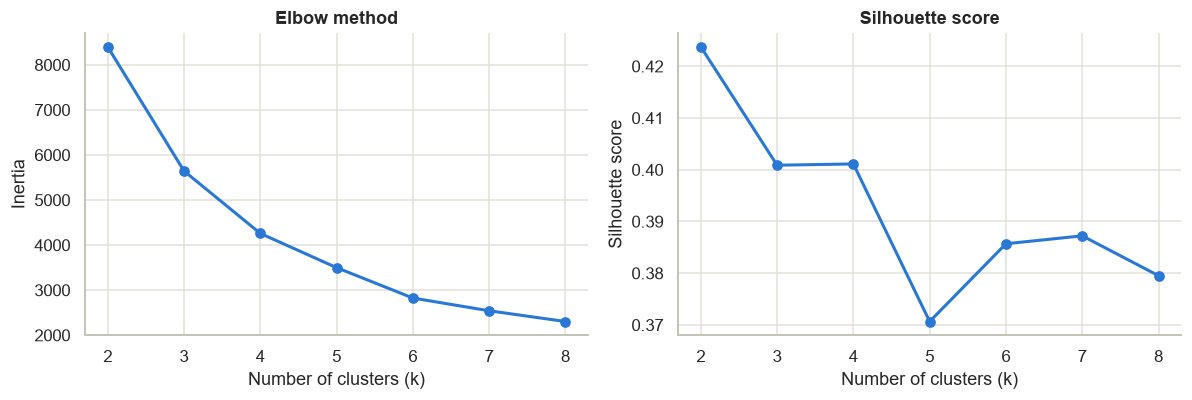

,inertia,silhouette
k,,
2,8399.0,0.424
3,5644.0,0.401
4,4259.0,0.401
5,3499.0,0.371
6,2824.0,0.386
7,2542.0,0.387
8,2303.0,0.380


In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

segment_scaled = StandardScaler().fit_transform(train_fe[SEGMENT_FEATURES])

k_values = list(range(2, 9))
inertias, silhouettes = [], []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(segment_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(segment_scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_values, inertias, marker="o", color=BLUE, linewidth=2)
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouettes, marker="o", color=BLUE, linewidth=2)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": k_values, "inertia": np.round(inertias), "silhouette": np.round(silhouettes, 3)}).set_index("k")

**Choice: k = 4.**
- k = 2 has the highest silhouette (0.42), but two groups are too coarse to describe customers usefully.
- k = 3 and k = 4 have the same silhouette (0.40), and it drops at k = 5 (0.37).
- The elbow curve bends around k = 4: inertia falls by about 2,750 and 1,390 for the first two
  steps, then by only 760 from k = 4 to 5.

So k = 4 is the largest k that keeps the silhouette at its plateau, and (below) it gives four
segments that are easy to describe.

In [22]:
N_SEGMENTS = 4

segmenter = SegmentAdder(n_clusters=N_SEGMENTS, random_state=RANDOM_STATE).fit(train_fe)
train_seg = segmenter.transform(train_fe).assign(Churn=y_train)

# Segment profile: the mean of each feature per cluster, plus size and churn rate
profile = train_seg.groupby("CustomerSegment")[SEGMENT_FEATURES + ["TotalCharges"]].mean().round(1)
profile.insert(0, "customers", train_seg["CustomerSegment"].value_counts())
profile["fiber_%"] = (train_seg.groupby("CustomerSegment")["IsFiber"].mean() * 100).round(0)
profile["no_internet_%"] = (train_seg.groupby("CustomerSegment")["NoInternet"].mean() * 100).round(0)
profile["month_to_month_%"] = (train_seg.groupby("CustomerSegment")["IsMonthToMonth"].mean() * 100).round(0)
profile["churn_rate_%"] = (train_seg.groupby("CustomerSegment")["Churn"].mean() * 100).round(1)
profile

,customers,TenureMonths,MonthlyCharges,NumServices,TotalCharges,fiber_%,no_internet_%,month_to_month_%,churn_rate_%
CustomerSegment,,,,,,,,,
S0,1779,16.8,78.8,2.6,1309.3,70.0,0.0,85.0,45.4
S1,762,53.5,29.4,0.8,1572.2,2.0,70.0,16.0,4.6
S2,1382,9.3,34.7,0.4,289.4,12.0,49.0,77.0,28.5
S3,1711,58.2,90.7,4.8,5275.9,62.0,0.0,24.0,15.1


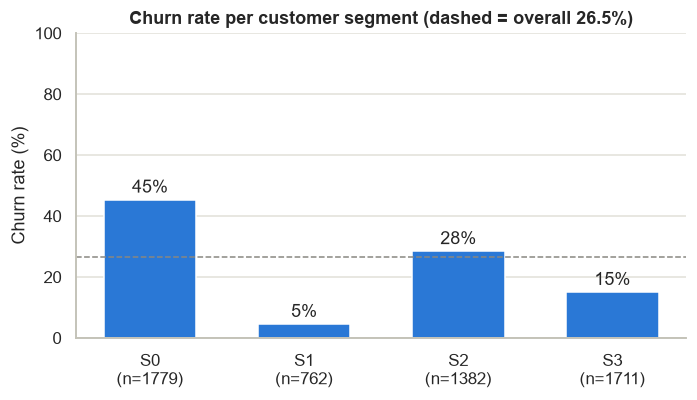

In [23]:
plt.figure(figsize=(6.5, 3.8))
bars = plt.bar([f"{s}\n(n={n})" for s, n in zip(profile.index, profile["customers"])],
               profile["churn_rate_%"], color=BLUE, width=0.6)
plt.bar_label(bars, fmt="%.0f%%", padding=2)
plt.axhline(y_train.mean() * 100, color=GREY, linestyle="--", linewidth=1)
plt.ylim(0, 100)
plt.ylabel("Churn rate (%)")
plt.title(f"Churn rate per customer segment (dashed = overall {y_train.mean():.1%})")
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**The four segments** (training set; the labels S0-S3 are arbitrary names given by K-Means)

| Segment | One-line description | Churn rate |
|---|---|---|
| **S0** | *Newer fiber customers on monthly contracts* - about 17 months tenure, high bill (about 79), 70% fiber, 85% month-to-month | 45.4% |
| **S1** | *Long-standing, low-bill customers* - about 54 months tenure, bill about 29, mostly without internet | 4.6% |
| **S2** | *New, low-bill customers with few services* - about 9 months tenure, bill about 35, 77% month-to-month | 28.5% |
| **S3** | *Loyal full-package customers* - about 58 months tenure, highest bill (about 91), almost 5 add-on services | 15.1% |

Segment S0 churns ten times as often as S1. It combines three of the EDA risk factors (fiber,
monthly contract, short tenure), so it is the obvious first target for retention. The high-value
S3 customers are fairly safe despite their high bills, because they are long-standing and use many services.

## 4. Preprocessing pipeline

### 4.1 Design

Everything that learns from data lives inside one scikit-learn `Pipeline`. During cross-validation
the whole pipeline is re-fitted on each training fold, so the validation fold never influences the
K-Means centres, the encoder categories or the scaler. That is what prevents **data leakage**.

| Step | What it does | Learned from training data |
|---|---|---|
| `features` | Builds the engineered features | nothing (fixed formulas) |
| `segment` | Adds `CustomerSegment` (included whenever that feature is selected, as in the final model) | scaler + K-Means centres |
| `preprocess` | `ColumnTransformer`: one-hot / ordinal / scaling | categories, means, standard deviations |
| `model` | The classifier | the model itself |

Inside the `ColumnTransformer`:
- **OneHotEncoder** for nominal columns (no natural order), e.g. `InternetService`, `PaymentMethod`;
- **OrdinalEncoder** for `Contract` (month-to-month < one year < two year) and `TenureGroup`, which do have an order;
- **StandardScaler** for numeric columns - needed by Logistic Regression and K-Means, harmless for trees.

Only the columns listed in `features` are passed on; everything else is dropped by the `ColumnTransformer`.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder

# Columns with an order, and the order of their categories
ORDINAL_CATEGORIES = {
    "Contract": ["Month-to-month", "One year", "Two year"],
    "TenureGroup": ["0-12", "13-24", "25-48", "49+"],
}
# Text columns without an order
NOMINAL_COLUMNS = ["Gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "InternetService",
                   "PaperlessBilling", "PaymentMethod", "CustomerSegment"] + ADDON_SERVICES


def build_preprocessor(features):
    # Send each selected feature to the right encoder / scaler.
    nominal = [f for f in features if f in NOMINAL_COLUMNS]
    ordinal = [f for f in features if f in ORDINAL_CATEGORIES]
    numeric = [f for f in features if f not in nominal and f not in ordinal]
    return ColumnTransformer(
        transformers=[
            # drop="if_binary": a Yes/No column becomes one 0/1 column instead of two
            ("nominal", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), nominal),
            ("ordinal", OrdinalEncoder(categories=[ORDINAL_CATEGORIES[f] for f in ordinal]), ordinal),
            ("numeric", StandardScaler(), numeric),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def build_pipeline(model, features, sampler=None):
    # Full pipeline: engineer features -> (segment) -> encode/scale -> (sampler) -> model
    steps = [("features", FunctionTransformer(add_features))]
    if "CustomerSegment" in features:
        steps.append(("segment", SegmentAdder(n_clusters=N_SEGMENTS, random_state=RANDOM_STATE)))
    steps.append(("preprocess", build_preprocessor(features)))
    if sampler is not None:                      # used only for the SMOTE comparison in Section 5
        from imblearn.pipeline import Pipeline as ImbPipeline
        return ImbPipeline(steps + [("sampler", sampler), ("model", model)])
    return Pipeline(steps + [("model", model)])

### 4.2 Class imbalance

26.5% of customers churn. We use `class_weight="balanced"`, which makes each churner count about
2.8 times as much as a stayer during training, so the model does not simply favour the majority
class. SMOTE is compared against this in Section 5.3.

### 4.3 Which features actually help? (ablation)

An **ablation test** adds one *group* of features at a time to the raw columns and measures the
5-fold cross-validated score on the training set. We use two different kinds of model so that a
feature is not judged by one model's taste: Logistic Regression (linear) and Random Forest (trees).

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ABLATION_MODELS = {
    "LogReg": LogisticRegression(class_weight="balanced", max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced",
                                           random_state=RANDOM_STATE, n_jobs=-1),
}


def cv_scores(features):
    # Mean 5-fold ROC-AUC and F1 on the training set for both ablation models.
    result = {"n_features": len(features)}
    for name, model in ABLATION_MODELS.items():
        scores = cross_validate(build_pipeline(model, features), X_train, y_train, cv=cv,
                                scoring=["roc_auc", "f1"])
        result[f"{name}_AUC"] = scores["test_roc_auc"].mean()
        result[f"{name}_F1"] = scores["test_f1"].mean()
    return result


# Raw columns kept after Section 2 (Gender, PhoneService and TotalCharges dropped)
RAW_FEATURES = ["SeniorCitizen", "Partner", "Dependents", "TenureMonths", "InternetService"] + ADDON_SERVICES + \
               ["Contract", "PaperlessBilling", "PaymentMethod", "MonthlyCharges"]

FEATURE_GROUPS = {
    "ratio features": ["AvgChargePerMonth", "ChargeDelta"],
    "threshold flags": ["IsNewCustomer", "IsMonthToMonth", "TenureGroup", "IsFiber", "NoInternet", "ElectronicCheck"],
    "summary features": ["NumServices", "HasStreaming", "AutoPay", "HasProtectionBundle"],
    "interactions": ["MonthToMonth_x_New", "Fiber_x_MonthToMonth"],
    "K-Means segment": ["CustomerSegment"],
}
ALL_ENGINEERED = sum(FEATURE_GROUPS.values(), [])

ablation = {"Raw columns (baseline)": cv_scores(RAW_FEATURES)}
for group, features in FEATURE_GROUPS.items():
    ablation[f"Raw + {group}"] = cv_scores(RAW_FEATURES + features)
ablation["Raw + all engineered features (FINAL set)"] = cv_scores(RAW_FEATURES + ALL_ENGINEERED)

# Fold-to-fold spread of the baseline, to judge how big a "real" difference must be
baseline_folds = cross_validate(build_pipeline(ABLATION_MODELS["LogReg"], RAW_FEATURES), X_train, y_train,
                                cv=cv, scoring=["roc_auc", "f1"])
print(f"Baseline LogReg, standard deviation across the 5 folds: "
      f"AUC {baseline_folds['test_roc_auc'].std():.3f}, F1 {baseline_folds['test_f1'].std():.3f}")

ablation_table = pd.DataFrame(ablation).T.astype({"n_features": int})
ablation_table.round(4)

Baseline LogReg, standard deviation across the 5 folds: AUC 0.013, F1 0.017


,n_features,LogReg_AUC,LogReg_F1,RandomForest_AUC,RandomForest_F1
Raw columns (baseline),16,0.8583,0.6429,0.8603,0.6430
Raw + ratio features,18,0.8578,0.6424,0.8600,0.6483
Raw + threshold flags,22,0.8609,0.6490,0.8607,0.6463
Raw + summary features,20,0.8585,0.6428,0.8601,0.6451
Raw + interactions,18,0.8612,0.6494,0.8609,0.6501
Raw + K-Means segment,17,0.8591,0.6395,0.8605,0.6445
Raw + all engineered features (FINAL set),31,0.8606,0.6451,0.8584,0.6518


**Reading the ablation table**

- **No group of engineered features changes the score beyond noise.** Every row is within about
  0.003 ROC-AUC of the baseline (Logistic Regression 0.858 -> 0.861 at best; Random Forest
  0.860 -> 0.861), while the score varies by about 0.013 from fold to fold.
- The best single additions for Logistic Regression are the **threshold flags** and the
  **interactions** (ROC-AUC 0.861 each). This makes sense: flags such as `IsFiber` and
  `Fiber_x_MonthToMonth` let a linear model express step changes it otherwise cannot. But the gain is
  too small to be sure it is real.
- **The full engineered set (the final set)** gives Logistic Regression ROC-AUC 0.861 and F1 0.645
  (baseline 0.858 / 0.643), and Random Forest 0.858 / 0.652 (baseline 0.860 / 0.643). All of these
  differences are inside the fold-to-fold noise.

**Honest conclusion:** the raw columns already contain almost all of the usable signal, so feature
engineering does not make the model measurably more accurate on this dataset. It does not make it
worse either. The assignment asks for engineered features and for K-Means to be part of the
solution, so **all 15 engineered features, including the K-Means `CustomerSegment`, are kept in
the final model.** They express the EDA findings directly (for example "fiber on a monthly
contract") and give the tree models ready-made splits.

In [26]:
# The final feature set, with the problem-statement category of each feature
FINAL_FEATURE_CATEGORIES = {
    **{f: "Demographic" for f in ["SeniorCitizen", "Partner", "Dependents"]},
    **{f: "Usage" for f in ["TenureMonths", "InternetService"] + ADDON_SERVICES},
    **{f: "Billing" for f in ["Contract", "PaperlessBilling", "PaymentMethod", "MonthlyCharges"]},
    **{f: "Usage" for f in ["NumServices", "HasStreaming", "IsFiber", "NoInternet", "IsNewCustomer", "TenureGroup"]},
    **{f: "Billing" for f in ["AvgChargePerMonth", "ChargeDelta", "IsMonthToMonth", "AutoPay", "ElectronicCheck"]},
    "HasProtectionBundle": "Service feedback (proxy)",
    "MonthToMonth_x_New": "Interaction", "Fiber_x_MonthToMonth": "Interaction",
    "CustomerSegment": "Usage + Billing (K-Means)",
}
FINAL_FEATURES = [f for f in FINAL_FEATURE_CATEGORIES if f in RAW_FEATURES + ALL_ENGINEERED]
assert sorted(FINAL_FEATURES) == sorted(RAW_FEATURES + ALL_ENGINEERED)

print(f"Final feature set: {len(FINAL_FEATURES)} features ({len(ALL_ENGINEERED)} engineered)")
for category in ["Demographic", "Usage", "Billing", "Service feedback (proxy)",
                 "Usage + Billing (K-Means)", "Interaction"]:
    members = [f for f in FINAL_FEATURES if FINAL_FEATURE_CATEGORIES[f] == category]
    print(f"  {category} ({len(members)}): {', '.join(members)}")

Final feature set: 31 features (15 engineered)
  Demographic (3): SeniorCitizen, Partner, Dependents
  Usage (15): TenureMonths, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, MultipleLines, NumServices, HasStreaming, IsFiber, NoInternet, IsNewCustomer, TenureGroup
  Billing (9): Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, AvgChargePerMonth, ChargeDelta, IsMonthToMonth, AutoPay, ElectronicCheck
  Service feedback (proxy) (1): HasProtectionBundle
  Usage + Billing (K-Means) (1): CustomerSegment
  Interaction (2): MonthToMonth_x_New, Fiber_x_MonthToMonth


**The final model uses 31 features: the 16 raw columns kept after Section 2 plus all 15 engineered
features.**

**Problem-statement categories:** 3 demographic, 15 usage and 9 billing features, plus the K-Means
segment (built from usage and billing columns) and 2 interaction features. **Service feedback is
represented only by the proxy `HasProtectionBundle`**, because the dataset has no genuine feedback
column (Section 2.2).

**A trade-off to be aware of.** Several final features overlap heavily (for example `Contract` and
`IsMonthToMonth`, `InternetService` and `IsFiber`/`NoInternet`, or `PaymentMethod`, `AutoPay`
and `ElectronicCheck`). This does not hurt prediction, but it means a Logistic Regression
coefficient is shared between overlapping features. In Section 6.3 the drivers are therefore read
by *theme*, not one coefficient at a time.

Because `CustomerSegment` is a model input, the pipeline fits the scaler and K-Means inside every
training fold, so the segments never see validation or test customers.

## 5. Models

### 5.1 Why these four models

No reference report was available, so each model is chosen on its own merits. We keep to four
well-known models that go from simple to powerful.

1. **Logistic Regression** - the interpretable baseline. Each coefficient says whether a feature
   pushes a customer towards churning or staying, and by how much. If a simple linear model does
   well, there is no reason to prefer a black box.
2. **Decision Tree (depth-limited)** - produces readable if/else rules that can be explained in a
   viva. Depth is limited because a deep tree memorises the training data.
3. **Random Forest** - averages hundreds of trees built on random samples, which makes it much more
   stable than a single tree and gives a feature-importance ranking. It is one of the models named
   in the assignment.
4. **Gradient Boosting** (`GradientBoostingClassifier`) - builds small trees one after another,
   each correcting the errors of the previous ones. It is usually the strongest scikit-learn model on tabular data.

K-Means is *not* a classifier (it never sees the `Churn` label), so it is not a fifth model.
Instead it builds the customer segments of Section 3.3, and the segment label is one of the
inputs to all four classifiers.

### 5.2 Tuning

Each model is tuned with `GridSearchCV` over a small grid, using 5-fold stratified
cross-validation on the training set. The grid search picks the setting with the best **F1 score
on the churn class**; ROC-AUC and recall are recorded as well. Accuracy is not used for tuning
because of the class imbalance.

`GradientBoostingClassifier` has no `class_weight` option, so it receives the same "balanced"
weights through `sample_weight` instead.

In [27]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

# model, small parameter grid ("model__" points at the last pipeline step)
MODEL_SETUPS = {
    "Logistic Regression": (
        LogisticRegression(class_weight="balanced", max_iter=1000),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"model__max_depth": [3, 4, 5, 6], "model__min_samples_leaf": [10, 25, 50]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [5, 10, 20]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE),
        {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3]},
    ),
}

balanced_weights = compute_sample_weight("balanced", y_train)

best_models, cv_rows = {}, []
for name, (model, grid) in MODEL_SETUPS.items():
    search = GridSearchCV(build_pipeline(model, FINAL_FEATURES), grid, cv=cv,
                          scoring=["f1", "roc_auc", "recall"], refit="f1")
    if name == "Gradient Boosting":
        search.fit(X_train, y_train, model__sample_weight=balanced_weights)
    else:
        search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_      # already re-fitted on the full training set
    best = search.best_index_
    # mean and standard deviation across the 5 validation folds, for the best setting
    cv_rows.append({
        "model": name,
        "cv_F1_mean": search.cv_results_["mean_test_f1"][best],
        "cv_F1_std": search.cv_results_["std_test_f1"][best],
        "cv_ROC_AUC_mean": search.cv_results_["mean_test_roc_auc"][best],
        "cv_ROC_AUC_std": search.cv_results_["std_test_roc_auc"][best],
        "cv_Recall_mean": search.cv_results_["mean_test_recall"][best],
        "best_parameters": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    })

cv_table = pd.DataFrame(cv_rows).set_index("model")
pd.set_option("display.max_colwidth", 100)
cv_table.round(3)

C:\Users\yashi\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\yashi\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\yashi\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\yashi\AppData\Roaming\Python\Pytho

,cv_F1_mean,cv_F1_std,cv_ROC_AUC_mean,cv_ROC_AUC_std,cv_Recall_mean,best_parameters
model,,,,,,
Logistic Regression,0.646,0.021,0.861,0.011,0.806,{'C': 0.1}
Decision Tree,0.629,0.005,0.844,0.004,0.821,"{'max_depth': 5, 'min_samples_leaf': 25}"
Random Forest,0.651,0.010,0.859,0.009,0.791,"{'max_depth': 8, 'min_samples_leaf': 5}"
Gradient Boosting,0.648,0.022,0.863,0.011,0.807,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}"


**Cross-validation results** (mean and standard deviation over the 5 validation folds)

- Logistic Regression, Random Forest and Gradient Boosting are practically tied: F1 0.646-0.651
  and ROC-AUC 0.859-0.863, while the fold-to-fold standard deviation is 0.01-0.02. The gaps
  between these three models are smaller than that spread, so they are **within noise**.
- The depth-limited Decision Tree is the weakest on F1 (0.629) and ROC-AUC (0.844), as expected.
- Recall on the churn class is already about 0.79-0.82 for every model, thanks to the balanced class weights.

### 5.3 Would SMOTE do better than class weights?

SMOTE creates synthetic churners until both classes are the same size. It is placed **inside** an
`imblearn` pipeline, so it only ever sees the training folds - the validation fold stays untouched.
We compare it with `class_weight="balanced"` on the tuned Logistic Regression and Random Forest.

In [28]:
from imblearn.over_sampling import SMOTE
from sklearn.base import clone

smote_rows = []
for name in ["Logistic Regression", "Random Forest"]:
    tuned = best_models[name].named_steps["model"]
    variants = {
        "class_weight='balanced'": build_pipeline(clone(tuned), FINAL_FEATURES),
        "SMOTE": build_pipeline(clone(tuned).set_params(class_weight=None), FINAL_FEATURES,
                                sampler=SMOTE(random_state=RANDOM_STATE)),
    }
    for variant, pipeline in variants.items():
        scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                                scoring=["recall", "precision", "f1", "roc_auc"])
        smote_rows.append({"model": name, "imbalance handling": variant,
                           "cv_Recall": scores["test_recall"].mean(),
                           "cv_Precision": scores["test_precision"].mean(),
                           "cv_F1": scores["test_f1"].mean(),
                           "cv_ROC_AUC": scores["test_roc_auc"].mean()})

pd.DataFrame(smote_rows).set_index(["model", "imbalance handling"]).round(3)

cv_Recall  cv_Precision  cv_F1  \
model               imbalance handling                                        
Logistic Regression class_weight='balanced'      0.806         0.539  0.646   
                    SMOTE                        0.803         0.540  0.646   
Random Forest       class_weight='balanced'      0.791         0.554  0.651   
                    SMOTE                        0.738         0.573  0.645   

                                             cv_ROC_AUC  
model               imbalance handling                   
Logistic Regression class_weight='balanced'       0.861  
                    SMOTE                         0.859  
Random Forest       class_weight='balanced'       0.859  
                    SMOTE                         0.859

**SMOTE does not help.** For Logistic Regression it gives the same result as class weights (recall
0.803 vs 0.806, F1 0.646 for both). For Random Forest it lowers recall clearly (0.738 vs 0.791) and
F1 slightly (0.645 vs 0.651). We keep `class_weight="balanced"`: it is simpler and does not invent
artificial customers.

## 6. Evaluation on the held-out test set

The 1,409 test customers have not been used for anything so far. Each tuned model now predicts them once.

**Which threshold each row uses.** The comparison table has a `Threshold` column. In the first
table every model uses the default threshold of **0.50**, so the models are compared on equal
terms. After the threshold is tuned in Section 6.2, the table is shown again with one extra row
for the chosen model at its tuned threshold.

**Cross-validation next to test.** Each row also shows the 5-fold cross-validation F1 and ROC-AUC
on the training set as mean ± standard deviation. The standard deviation tells us how much a score
moves just from changing the data split, i.e. how big a difference must be before it means anything.

**Leakage guard.** For this dataset a ROC-AUC of about 0.84-0.86 is typical. A score above about
0.95 would be a warning sign that a leaking column (such as `ChurnScore`) had slipped through,
so the next cell checks for that before we interpret anything.

In [29]:
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_curve)


def evaluate(model, X, y, threshold=0.5):
    # Test metrics for one fitted pipeline at a given decision threshold.
    probability = model.predict_proba(X)[:, 1]
    prediction = (probability >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y, prediction),
            "Precision": precision_score(y, prediction),
            "Recall": recall_score(y, prediction),
            "F1": f1_score(y, prediction),
            "ROC-AUC": roc_auc_score(y, probability)}


def comparison_row(threshold, cv_f1_mean, cv_f1_std, cv_auc_mean, cv_auc_std, test_scores):
    # One row of the comparison table: threshold, CV mean +/- std, then the test scores.
    return {"Threshold": threshold,
            "CV F1 (mean ± std)": f"{cv_f1_mean:.3f} ± {cv_f1_std:.3f}",
            "CV ROC-AUC (mean ± std)": f"{cv_auc_mean:.3f} ± {cv_auc_std:.3f}",
            **{f"Test {metric}": round(value, 3) for metric, value in test_scores.items()}}


comparison_rows = {}
for name, model in best_models.items():
    cv_row = cv_table.loc[name]
    comparison_rows[name] = comparison_row(0.50, cv_row["cv_F1_mean"], cv_row["cv_F1_std"],
                                           cv_row["cv_ROC_AUC_mean"], cv_row["cv_ROC_AUC_std"],
                                           evaluate(model, X_test, y_test, threshold=0.50))

test_table = pd.DataFrame(comparison_rows).T

# Leakage guard: stop here if any model is suspiciously good
assert test_table["Test ROC-AUC"].max() < 0.95, "ROC-AUC above 0.95 - check for leakage before continuing!"
print("Leakage guard passed: highest test ROC-AUC =", test_table["Test ROC-AUC"].max())
test_table

Leakage guard passed: highest test ROC-AUC = 0.853


,Threshold,CV F1 (mean ± std),CV ROC-AUC (mean ± std),Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
Logistic Regression,0.5,0.646 ± 0.021,0.861 ± 0.011,0.752,0.522,0.781,0.626,0.853
Decision Tree,0.5,0.629 ± 0.005,0.844 ± 0.004,0.735,0.5,0.821,0.621,0.842
Random Forest,0.5,0.651 ± 0.010,0.859 ± 0.009,0.769,0.545,0.786,0.644,0.853
Gradient Boosting,0.5,0.648 ± 0.022,0.863 ± 0.011,0.759,0.531,0.786,0.634,0.852


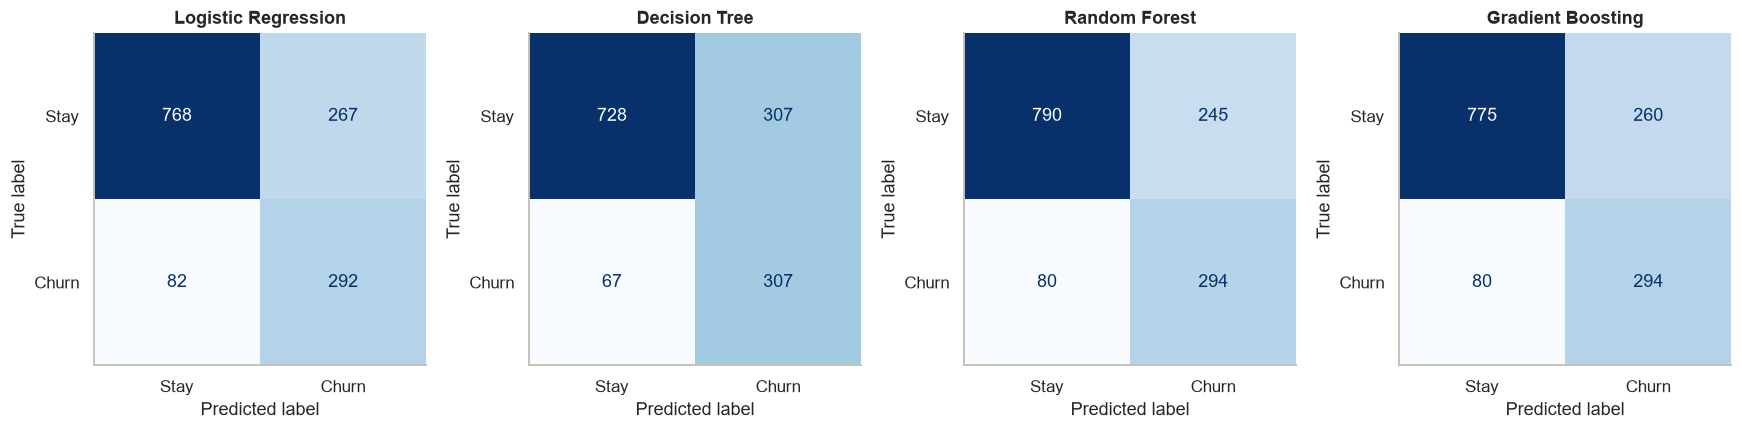

In [30]:
# Confusion matrices (rows = what really happened, columns = what the model predicted)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["Stay", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

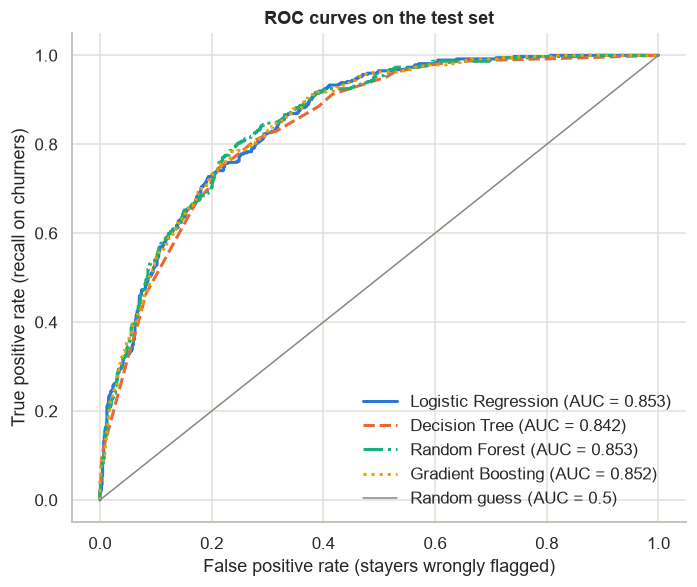

In [31]:
# ROC curves on one plot
MODEL_STYLES = {"Logistic Regression": (BLUE, "-"), "Decision Tree": (ORANGE, "--"),
                "Random Forest": ("#1baf7a", "-."), "Gradient Boosting": ("#eda100", ":")}

plt.figure(figsize=(6.5, 5.5))
for name, model in best_models.items():
    probability = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    color, style = MODEL_STYLES[name]
    plt.plot(fpr, tpr, color=color, linestyle=style, linewidth=2,
             label=f"{name} (AUC = {roc_auc_score(y_test, probability):.3f})")
plt.plot([0, 1], [0, 1], color=GREY, linewidth=1, label="Random guess (AUC = 0.5)")
plt.xlabel("False positive rate (stayers wrongly flagged)")
plt.ylabel("True positive rate (recall on churners)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

**Test-set results (all four models at threshold 0.50)**

- **Random Forest** has the highest F1 (0.644), precision (0.545) and accuracy (0.769), with
  ROC-AUC 0.853.
- **Logistic Regression** has the same ROC-AUC (0.853), recall 0.781 and F1 0.626.
- **Gradient Boosting** is in between (F1 0.634, ROC-AUC 0.852).
- **Decision Tree** has the highest recall (0.821) but the lowest precision (0.500) and ROC-AUC
  (0.842): half of the customers it flags would have stayed.

**Are the three strong models really different? No - they are within noise.**
- In cross-validation the F1 scores differ by at most 0.005 (0.646-0.651) and the ROC-AUCs by at
  most 0.004 (0.859-0.863), while the fold-to-fold standard deviation is 0.01-0.02.
- On the test set, ROC-AUC is identical to two decimals (0.85) for all three. The F1 gap of 0.018
  between Random Forest and Logistic Regression is the size of the cross-validation standard
  deviation, i.e. within what a different split could produce.

So the scores alone cannot pick a winner. **Logistic Regression is chosen for its
interpretability:** it is the simplest of the three, each coefficient has a direction and a size
that can be explained to a manager, and nothing measurable is lost by choosing it.

**Why the scores look the way they do.** ROC-AUC of about 0.85 is in the normal range for this
dataset (0.84-0.86) and well below the 0.95 leakage warning line, so there is no sign that a
leaking column slipped through. It is clearly higher than chance because the drivers are strong
(contract type alone separates 43% from 3% churn). It is not higher still because many customers
in risky groups do stay: precision is only about 0.52-0.55, so roughly half of the flagged
customers would not have churned. Test scores are close to the cross-validation scores, so the
models are **not overfitting**.

### 6.1 Why recall on the churn class matters most

The two kinds of mistake do not cost the same:

- **False negative (missed churner):** the model says "stay", the customer leaves. The company
  loses all the future revenue from that customer and has to pay to acquire a replacement.
- **False positive (false alarm):** the model says "churn", the customer was going to stay anyway.
  The cost is one unnecessary retention call or discount.

A missed churner is far more expensive than a false alarm, so we would rather catch more churners
(**high recall**) and accept some extra false alarms (lower precision). Precision still matters,
because if nearly every customer is flagged the retention team cannot act on the list.

### 6.2 Tuning the decision threshold

A model outputs a churn *probability*; the threshold decides when that becomes a "churn"
prediction. Lowering it catches more churners (recall up) but raises more false alarms
(precision down); raising it does the opposite.

To keep the test set clean, the threshold is chosen using **out-of-fold predictions on the
training set**: each training customer is scored by a model that did not see them. Our business
rule: *catch at least 80% of churners*, and among the thresholds that achieve this pick the
highest one (which gives the best precision).

Out-of-fold recall at the default 0.50 threshold: 0.806
Chosen threshold: 0.51  (threshold with the best F1 would be 0.55)


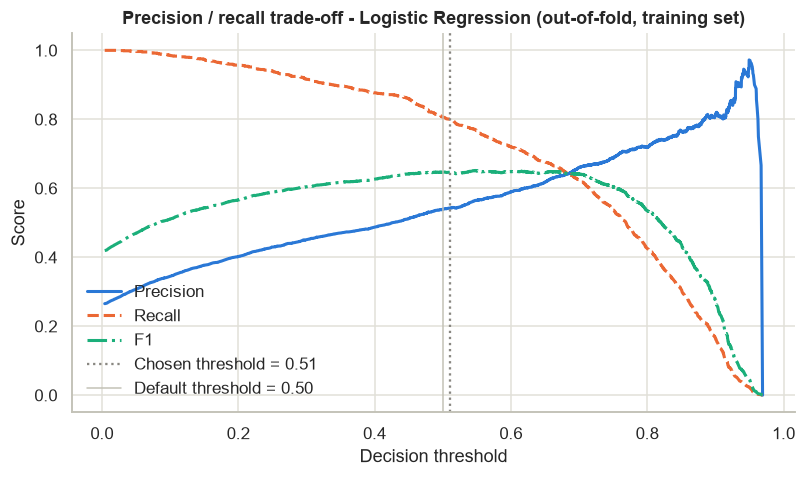

In [32]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

BEST_MODEL_NAME = "Logistic Regression"
TARGET_RECALL = 0.80
final_model = best_models[BEST_MODEL_NAME]

# Out-of-fold churn probabilities for the training customers
oof_probability = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_probability)
precision, recall = precision[:-1], recall[:-1]          # align with `thresholds`
with np.errstate(invalid="ignore"):                         # 0 / 0 at the extreme thresholds
    f1 = np.nan_to_num(2 * precision * recall / (precision + recall))

# Highest threshold that still reaches the recall target, rounded down to 2 decimals
best_threshold = float(np.floor(thresholds[recall >= TARGET_RECALL].max() * 100) / 100)
print(f"Out-of-fold recall at the default 0.50 threshold: {recall[thresholds >= 0.5][0]:.3f}")
print(f"Chosen threshold: {best_threshold:.2f}  (threshold with the best F1 would be {thresholds[f1.argmax()]:.2f})")

plt.figure(figsize=(7.5, 4.5))
plt.plot(thresholds, precision, color=BLUE, linewidth=2, label="Precision")
plt.plot(thresholds, recall, color=ORANGE, linewidth=2, linestyle="--", label="Recall")
plt.plot(thresholds, f1, color="#1baf7a", linewidth=2, linestyle="-.", label="F1")
plt.axvline(best_threshold, color=GREY, linestyle=":", linewidth=1.5, label=f"Chosen threshold = {best_threshold:.2f}")
plt.axvline(0.5, color="#c3c2b7", linewidth=1, label="Default threshold = 0.50")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title(f"Precision / recall trade-off - {BEST_MODEL_NAME} (out-of-fold, training set)")
plt.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

In [33]:
# Final comparison table: the four models at threshold 0.50, plus the chosen model at its tuned threshold.
# CV F1 for the tuned row = F1 of the out-of-fold predictions in each of the 5 validation folds.
# (ROC-AUC does not depend on the threshold, so it is the same as in the 0.50 row.)
fold_f1 = [f1_score(y_train.iloc[val], (oof_probability[val] >= best_threshold).astype(int))
           for _, val in cv.split(X_train, y_train)]
cv_row = cv_table.loc[BEST_MODEL_NAME]

TUNED_ROW = f"{BEST_MODEL_NAME} @ threshold {best_threshold:.2f}"
comparison_rows[TUNED_ROW] = comparison_row(best_threshold, np.mean(fold_f1), np.std(fold_f1),
                                            cv_row["cv_ROC_AUC_mean"], cv_row["cv_ROC_AUC_std"],
                                            evaluate(final_model, X_test, y_test, best_threshold))
final_table = pd.DataFrame(comparison_rows).T
display(final_table)

tuned_prediction = (final_model.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, tuned_prediction).ravel()
print(f"With the tuned threshold, out of {tp + fn} real churners in the test set: {tp} caught, {fn} missed.")
print(f"Customers flagged: {tp + fp} of {len(y_test)}, of which {fp} are false alarms.")

,Threshold,CV F1 (mean ± std),CV ROC-AUC (mean ± std),Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
Logistic Regression,0.5,0.646 ± 0.021,0.861 ± 0.011,0.752,0.522,0.781,0.626,0.853
Decision Tree,0.5,0.629 ± 0.005,0.844 ± 0.004,0.735,0.5,0.821,0.621,0.842
Random Forest,0.5,0.651 ± 0.010,0.859 ± 0.009,0.769,0.545,0.786,0.644,0.853
Gradient Boosting,0.5,0.648 ± 0.022,0.863 ± 0.011,0.759,0.531,0.786,0.634,0.852
Logistic Regression @ threshold 0.51,0.51,0.647 ± 0.024,0.861 ± 0.011,0.756,0.527,0.778,0.629,0.853


With the tuned threshold, out of 374 real churners in the test set: 291 caught, 83 missed.
Customers flagged: 552 of 1409, of which 261 are false alarms.


**Reading the final comparison table.** The first four rows use threshold **0.50**. The last row,
*Logistic Regression @ threshold 0.51*, is the same fitted model with the tuned threshold; only
the cut-off changed, so its ROC-AUC is identical.

**Effect of the tuned threshold (0.51 instead of 0.50)**

- Thanks to the balanced class weights, the model already catches about 80% of churners at the
  default threshold (out-of-fold recall 0.806). The rule "highest threshold that still reaches 80%
  recall" therefore moves the threshold only slightly *up*, to 0.51, which buys a little precision.
- On the test set: recall 0.778 (291 of 374 churners caught, 83 missed), precision 0.527, F1 0.629.
  Practically the same as at 0.50 (recall 0.781, precision 0.522, F1 0.626).
- The price of this recall is 261 false alarms: 552 of the 1,409 test customers are flagged.
- The 80% recall target was set on the training folds; on the test set it comes out at 77.8%,
  a normal amount of sampling variation.

The threshold is a business dial, not a fixed property of the model. If retention offers are
cheap, lower it; if the retention team is small, raise it. The plot above shows what each choice costs.

### 6.3 What drives churn?

Two views of the same question:
- **Feature importance** (Random Forest, Gradient Boosting): how much each feature is used to split the data. It shows *strength* but not *direction*.
- **Logistic Regression coefficients:** numeric features are standardised, so a coefficient is the effect of a one-standard-deviation increase. The sign gives the *direction* (positive = more likely to churn).

**How to read these with overlapping features.** The final model contains groups of features that
measure the same thing (for example `Contract` and `IsMonthToMonth`, or `InternetService` and
`IsFiber`). Such features *share* the credit: each one's importance or coefficient looks smaller
than the theme's real effect, and an individual sign can even flip. So we read the charts by
theme, adding up related features.

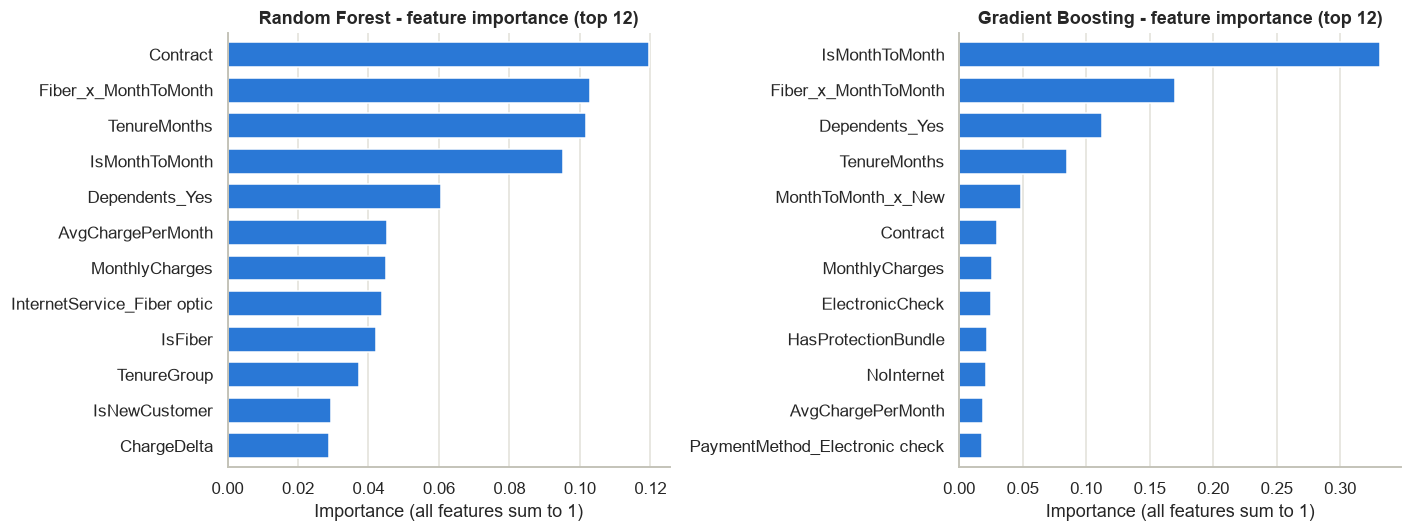

In [34]:
def feature_names(model):
    return model.named_steps["preprocess"].get_feature_names_out()


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["Random Forest", "Gradient Boosting"]):
    model = best_models[name]
    importance = pd.Series(model.named_steps["model"].feature_importances_, index=feature_names(model))
    importance.sort_values().tail(12).plot.barh(ax=ax, color=BLUE, width=0.7)
    ax.set_title(f"{name} - feature importance (top 12)")
    ax.set_xlabel("Importance (all features sum to 1)")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

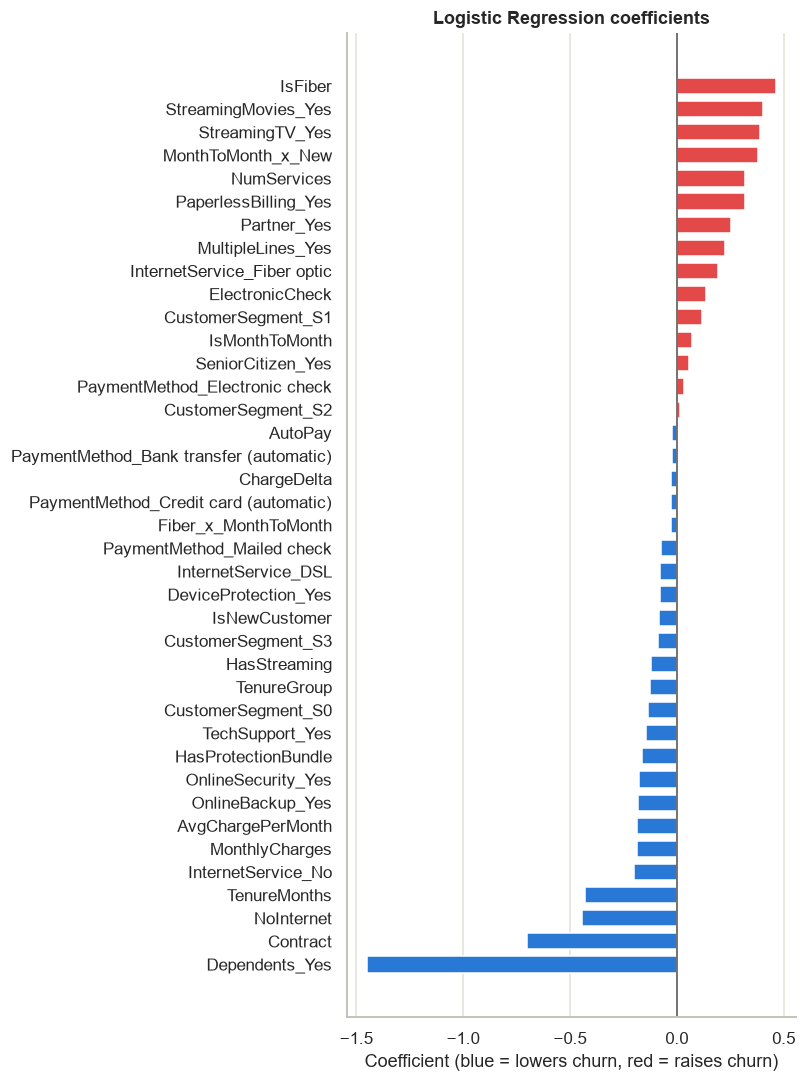

,coefficient,odds_ratio,direction
Dependents_Yes,-1.450,0.23,lowers churn
Contract,-0.700,0.50,lowers churn
IsFiber,0.464,1.59,raises churn
NoInternet,-0.445,0.64,lowers churn
TenureMonths,-0.431,0.65,lowers churn
StreamingMovies_Yes,0.403,1.50,raises churn
StreamingTV_Yes,0.388,1.47,raises churn
MonthToMonth_x_New,0.378,1.46,raises churn
NumServices,0.321,1.38,raises churn
PaperlessBilling_Yes,0.317,1.37,raises churn


In [35]:
logreg = best_models["Logistic Regression"]
coefficients = pd.Series(logreg.named_steps["model"].coef_[0], index=feature_names(logreg)).sort_values()

plt.figure(figsize=(7.5, 10))
plt.barh(coefficients.index, coefficients.values, height=0.7,
         color=[RED if value > 0 else BLUE for value in coefficients.values])
plt.axvline(0, color="#52514e", linewidth=1)
plt.xlabel("Coefficient (blue = lowers churn, red = raises churn)")
plt.title("Logistic Regression coefficients")
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

# Top 10 by absolute size, with the odds ratio (how the odds of churning are multiplied)
top10 = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(10)
pd.DataFrame({"coefficient": top10.round(3),
              "odds_ratio": np.exp(top10).round(2),
              "direction": np.where(top10 > 0, "raises churn", "lowers churn")})

**Reading the plots**
- **Contract** is the strongest single driver: 43% of month-to-month customers churn, against
  11% on one-year and only 3% on two-year contracts.
- **Internet service:** fiber-optic customers churn at 42%, more than twice the DSL rate (19%);
  customers without internet hardly churn at all (7%).
- **Payment method:** electronic-check payers churn at 45%, roughly three times the rate of
  automatic payers (15-17%) and well above mailed-check payers (19%).
- **Tenure:** churn falls steadily from 53% in the first 6 months to 10% after 4 years.
- **Monthly charges:** the cheapest fifth churns least (9%); above that the rate is 25-36%.
- **Tech support / online security:** customers with these add-ons churn about half as often (15% vs 31%).
- **Senior citizens** churn more (42% vs 24%), and **customers with dependents** churn much less (7% vs 33%)._MODEL

In [36]:
# The tuned Decision Tree as readable rules (first 3 levels).
import re
from sklearn.tree import export_text

tree = best_models["Decision Tree"]
rules = export_text(tree.named_steps["model"], feature_names=list(feature_names(tree)), max_depth=2)

# The tree was trained on standardised numbers. Convert each split value back to real units
# (value x standard deviation + mean) so the rules can be read directly.
scaler = tree.named_steps["preprocess"].named_transformers_["numeric"]
scaled_columns = list(scaler.feature_names_in_)


def to_real_units(match):
    name, sign, value = match.group(1), match.group(2), float(match.group(3))
    if name in scaled_columns:
        i = scaled_columns.index(name)
        value = value * scaler.scale_[i] + scaler.mean_[i]
    return f"{name} {sign} {value:.1f}"


print(re.sub(r"(\w+) (<=|>) +(-?\d+\.\d+)", to_real_units, rules))
print("Contract: 0 = month-to-month, 1 = one year, 2 = two year.  class 1 = churn, class 0 = stay.")
print("TenureGroup: 0 = 0-12 months, 1 = 13-24, 2 = 25-48, 3 = 49+.  Yes/No flags: 0 = no, 1 = yes.")

|--- IsMonthToMonth <= 0.5
|   |--- Dependents_Yes <= 0.5
|   |   |--- MonthlyCharges <= 93.6
|   |   |   |--- truncated branch of depth 3
|   |   |--- MonthlyCharges > 93.6
|   |   |   |--- truncated branch of depth 3
|   |--- Dependents_Yes > 0.5
|   |   |--- class: 0
|--- IsMonthToMonth > 0.5
|   |--- Fiber_x_MonthToMonth <= 0.5
|   |   |--- TenureMonths <= 5.5
|   |   |   |--- truncated branch of depth 3
|   |   |--- TenureMonths > 5.5
|   |   |   |--- truncated branch of depth 3
|   |--- Fiber_x_MonthToMonth > 0.5
|   |   |--- Dependents_Yes <= 0.5
|   |   |   |--- truncated branch of depth 3
|   |   |--- Dependents_Yes > 0.5
|   |   |   |--- truncated branch of depth 3

Contract: 0 = month-to-month, 1 = one year, 2 = two year.  class 1 = churn, class 0 = stay.
TenureGroup: 0 = 0-12 months, 1 = 13-24, 2 = 25-48, 3 = 49+.  Yes/No flags: 0 = no, 1 = yes.


## 7. Conclusion

### 7.1 Best model

**Logistic Regression with a decision threshold of 0.51** is the final model.

| Reason | Evidence |
|---|---|
| Scores as good as any model | Test ROC-AUC 0.853 (tied best), recall 0.778, F1 0.629; cross-validation F1 0.646 ± 0.021 and ROC-AUC 0.861 ± 0.011 |
| Not beaten by the ensembles | Random Forest and Gradient Boosting are within noise of it (gaps smaller than one cross-validation standard deviation), so their extra complexity buys nothing measurable |
| Most interpretable | Chosen over Random Forest and Gradient Boosting for this reason: every coefficient has a direction and a size that can be explained |
| Catches most churners | 291 of 374 test churners identified |
| Stable, no leakage | Cross-validation and test scores agree, and every score is far below the 0.95 leakage warning line |

The model uses 31 features, 15 of them engineered, including the K-Means customer segment.
Random Forest and Gradient Boosting remain useful as a cross-check: their feature importances point
to the same top themes (contract, tenure, fiber, dependents).

### 7.2 Business recommendations

1. **Move month-to-month customers onto longer contracts.** Contract type is the strongest driver
   (43% churn month-to-month vs 3% on two-year). Offer a discount or a free add-on for a one-year contract.
2. **Fix the fiber experience.** Fiber customers churn at 42%, and a third of churners left for a
   competitor offering faster speeds, more data or a better deal. Review fiber pricing and
   reliability, and target segment S0 (newer fiber customers on monthly contracts, 45% churn) first.
3. **Run an onboarding programme for the first 6-12 months.** Over half of customers churn in their
   first 6 months. Check in early, especially with new month-to-month customers.
4. **Bundle security and tech support, and improve support quality.** Customers with these add-ons
   churn about half as often, and "attitude of support person" is the most common churn reason.
   Offer the add-ons free for the first months and invest in support-staff training.
5. **Move electronic-check payers to automatic payment.** They churn at 45%, against 15-17% for
   automatic payers. Offer a small incentive to switch to card or bank-transfer auto-pay.

Use the model to rank customers by churn probability each month, so the retention budget goes to
the customers most at risk first.

### 7.3 Limitations

- **No service-feedback data.** The problem statement asks for service feedback, but the only such
  column (`ChurnReason`) is leakage. The model uses a proxy (`HasProtectionBundle`); real survey or
  complaint data would probably improve it.
- **Leaking columns had to be removed.** `ChurnScore` and `ChurnReason` would have produced
  near-perfect but meaningless scores. `CLTV` was also excluded; it could optionally be tested as an input.
- **Moderate precision.** About half of the flagged customers would not have churned (precision
  about 0.53). The model is good for *prioritising* customers, not for certainty.
- **Engineered features did not improve accuracy.** The ablation shows the same scores with and
  without them. They are in the final model because they cost nothing and express the EDA
  findings directly, not because they add predictive power.
- **Overlapping features blur individual coefficients.** Related features share credit, so the
  drivers are reliable by theme but not coefficient by coefficient.
- **Sample data from one region, one snapshot.** This is IBM's sample dataset of a fictional
  telecom company, with every customer in California and no dates. Behaviour changing over time
  cannot be seen, and results may not transfer to real customers or other markets.
- **Correlation is not causation.** The drivers show who churns, not what would happen if we intervened.
  Recommendations should be tested with a controlled trial (A/B test).
- **The threshold assumes a business rule** (catch 80% of churners). The right value depends on
  the real cost of a retention offer versus a lost customer.
- **No reference report.** The model choices could not be linked to the report mentioned in the assignment.

### 7.4 Save the final model and predict for a new customer

The saved file contains the full pipeline (feature engineering, K-Means segments, encoding,
scaling and the model), the tuned threshold and the list of features used. `churn_features.py`
must sit next to it, because the pipeline uses the classes defined there.

`predict_churn()` takes one customer as a dict. Keys can be the CamelCase names used in this
notebook (as below) or the original names from the Excel file (`"Tenure Months"`); `clean_data()`
converts them, and columns the model does not use (such as `CustomerID`) are ignored.

In [37]:
import joblib

joblib.dump({"pipeline": final_model, "threshold": best_threshold, "features": FINAL_FEATURES},
            "churn_model.pkl")
print("Saved churn_model.pkl")


def predict_churn(customer_dict, model_path="churn_model.pkl"):
    # Predict churn for one customer given as a dict of the original input columns.
    saved = joblib.load(model_path)
    customer = clean_data(pd.DataFrame([customer_dict]))        # same cleaning rules as training
    probability = float(saved["pipeline"].predict_proba(customer)[0, 1])
    return {"churn_probability": round(probability, 3),
            "prediction": "Churn" if probability >= saved["threshold"] else "Stay",
            "threshold_used": saved["threshold"]}


# Example: a new fiber customer on a month-to-month contract, paying by electronic check, no add-ons
example_customer = {
    "CustomerID": "NEW-0001", "Gender": "Female", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No",
    "TenureMonths": 3, "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 85.5, "TotalCharges": 256.5,
}
print("High-risk example:", predict_churn(example_customer))

# A long-standing DSL customer on a two-year contract with support add-ons and automatic payment
loyal_customer = {**example_customer, "Partner": "Yes", "Dependents": "Yes", "TenureMonths": 60,
                  "InternetService": "DSL", "OnlineSecurity": "Yes", "TechSupport": "Yes",
                  "Contract": "Two year", "PaymentMethod": "Credit card (automatic)",
                  "MonthlyCharges": 65.0, "TotalCharges": 3900.0}
print("Low-risk example :", predict_churn(loyal_customer))

Saved churn_model.pkl
High-risk example: {'churn_probability': 0.905, 'prediction': 'Churn', 'threshold_used': 0.51}
Low-risk example : {'churn_probability': 0.015, 'prediction': 'Stay', 'threshold_used': 0.51}
